# Análisis Multivariado de Varianza
## Ejemplo: Comparación de Métodos de Enseñanza
## Actividad 6. MANOVA
### Dr. Hugo García Tecocoatzi

**Alumno:** Rafael Santamaria Heredia  
**Matrícula:** A01646667  
**Institución:** Tecnológico de Monterrey, Campus Guadalajara

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from sklearn.datasets import load_iris, load_wine, load_diabetes # Necesaria para la actividad
from scipy.stats import f_oneway
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

import statsmodels.api as sm
from statsmodels.formula.api import ols

%matplotlib inline

In [2]:
# Generar datos sintéticos para el ejemplo
np.random.seed(42)

# Parámetros
n_por_grupo = 30
grupos = ['A', 'B', 'C']

# Método A: Enseñanza tradicional
# Matemáticas: media 75, Lectura: media 70
mat_A = np.random.normal(75, 8, n_por_grupo)
lec_A = np.random.normal(70, 8, n_por_grupo)

# Método B: Enseñanza activa
# Matemáticas: media 82, Lectura: media 78
mat_B = np.random.normal(82, 8, n_por_grupo)
lec_B = np.random.normal(78, 8, n_por_grupo)

# Método C: Enseñanza híbrida
# Matemáticas: media 78, Lectura: media 75
mat_C = np.random.normal(78, 8, n_por_grupo)
lec_C = np.random.normal(75, 8, n_por_grupo)

# Crear DataFrame
df = pd.DataFrame({
    'Metodo': ['A']*n_por_grupo + ['B']*n_por_grupo + ['C']*n_por_grupo,
    'Matematicas': np.concatenate([mat_A, mat_B, mat_C]),
    'Lectura': np.concatenate([lec_A, lec_B, lec_C])
})

# Asegurar que las calificaciones estén en rango [0, 100]
df['Matematicas'] = np.clip(df['Matematicas'], 0, 100)
df['Lectura'] = np.clip(df['Lectura'], 0, 100)

print("Datos generados exitosamente")
print(f"Forma del dataset: {df.shape}")
print(f"Grupos: {df['Metodo'].unique()}")
df.head(10)

Datos generados exitosamente
Forma del dataset: (90, 3)
Grupos: <StringArray>
['A', 'B', 'C']
Length: 3, dtype: str


,Metodo,Matematicas,Lectura
0,A,78.973713,65.186347
1,A,73.893886,84.818225
2,A,80.181508,69.892022
3,A,87.184239,61.538313
4,A,73.126773,76.580359
5,A,73.126904,60.233251
6,A,87.633703,71.670909
7,A,81.139478,54.322639
8,A,71.244205,59.374512
9,A,79.340480,71.574890


In [3]:
#  Estadísticas descriptivas por grupo
print("ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: \n")

estadisticas = df.groupby('Metodo').agg({
    'Matematicas': ['mean', 'std', 'min', 'max'],
    'Lectura': ['mean', 'std', 'min', 'max']
}).round(2)

print(estadisticas)

ESTADÍSTICAS DESCRIPTIVAS POR GRUPO: 

       Matematicas                     Lectura                    
              mean   std    min    max    mean   std    min    max
Metodo                                                            
A            73.49  7.20  59.69  87.63   69.03  7.45  54.32  84.82
B            82.10  7.94  61.04  94.52   77.84  7.27  62.65  97.71
C            77.24  8.19  65.14  95.52   77.23  7.58  65.47  96.76


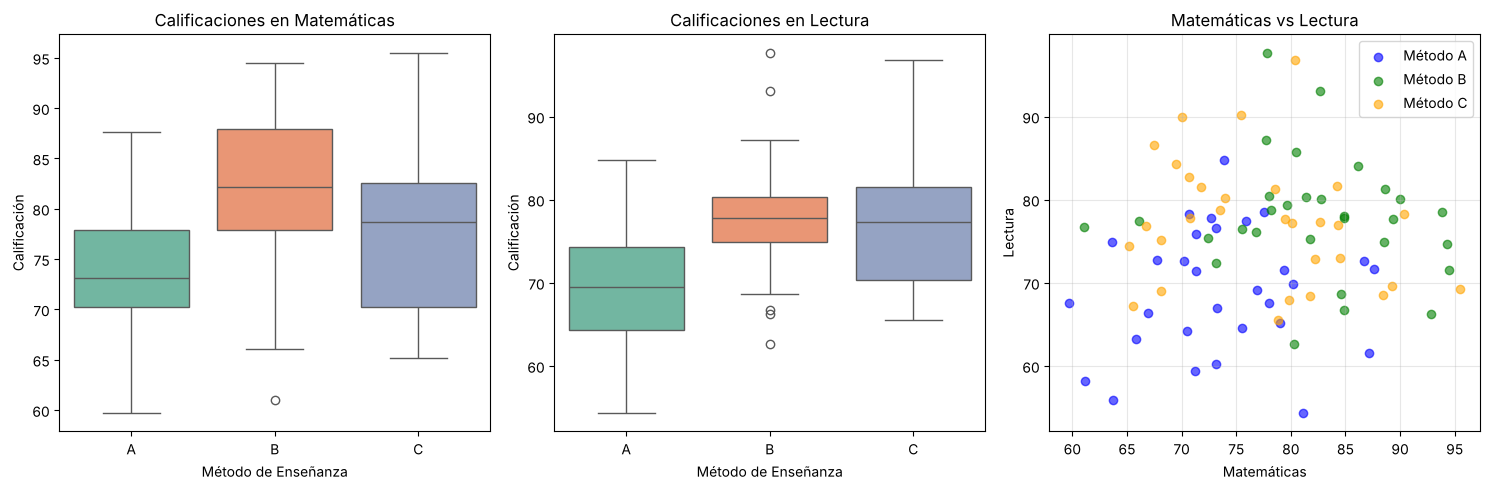

In [4]:
# Visualización 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot Matemáticas
sns.boxplot(x='Metodo', y='Matematicas', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Calificaciones en Matemáticas')
axes[0].set_xlabel('Método de Enseñanza')
axes[0].set_ylabel('Calificación')

# Boxplot Lectura
sns.boxplot(x='Metodo', y='Lectura', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Calificaciones en Lectura')
axes[1].set_xlabel('Método de Enseñanza')
axes[1].set_ylabel('Calificación')

# Scatter plot Matemáticas vs Lectura
colors = {'A': 'blue', 'B': 'green', 'C': 'orange'}
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo]
    axes[2].scatter(subset['Matematicas'], subset['Lectura'], 
                    alpha=0.6, label=f'Método {metodo}', color=colors[metodo])
axes[2].set_xlabel('Matemáticas')
axes[2].set_ylabel('Lectura')
axes[2].set_title('Matemáticas vs Lectura')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

MATRIZ DE CORRELACIÓN

             Matematicas  Lectura
Matematicas       1.0000   0.0886
Lectura           0.0886   1.0000


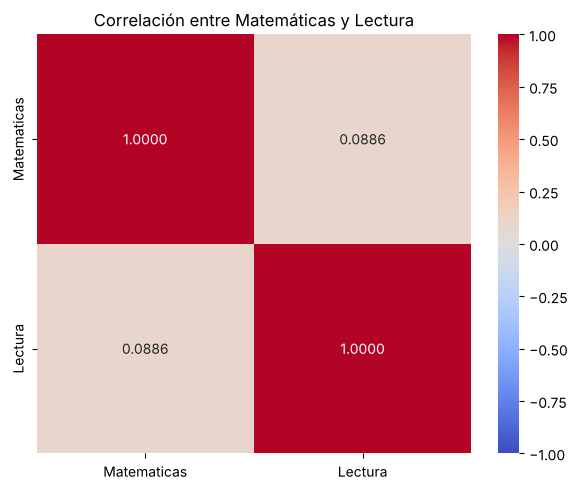

In [5]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[['Matematicas', 'Lectura']].corr().round(4))

# Visualización
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Matematicas', 'Lectura']].corr(), 
            annot=True, cmap='coolwarm', center=0, 
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre Matemáticas y Lectura')
plt.tight_layout()
plt.show()

In [6]:
#  MANOVA - Prueba principal
print("MANOVA \n")

# Ajustar MANOVA
manova = MANOVA.from_formula('Matematicas + Lectura ~ Metodo', data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                               
---------------------------------------------------------------
       Intercept         Value  Num DF  Den DF  F Value  Pr > F
---------------------------------------------------------------
          Wilks' lambda  0.0146 2.0000 86.0000 2907.3547 0.0000
         Pillai's trace  0.9854 2.0000 86.0000 2907.3547 0.0000
 Hotelling-Lawley trace 67.6129 2.0000 86.0000 2907.3547 0.0000
    Roy's greatest root 67.6129 2.0000 86.0000 2907.3547 0.0000
---------------------------------------------------------------
                                                               
---------------------------------------------------------------
           Metodo         Value  Num DF  Den DF  F Value Pr > F
---------------------------------------------------------------
            Wilks' lambda 0.6317 4.0000 172.0000 11.1040 0.0000
           Pillai's trace 0.3790 4.0000 174.0000 1

In [7]:
#  Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

# Extraer resultados del MANOVA
resultados_mv = manova.mv_test().results['Metodo']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                           Value Num DF      Den DF    F Value Pr > F
Wilks' lambda           0.631651      4       172.0  11.104044    0.0
Pillai's trace          0.379027    4.0       174.0  10.171469    0.0
Hotelling-Lawley trace  0.566246      4  102.169014  12.128592    0.0
Roy's greatest root     0.534625      2          87  23.256178    0.0


In [8]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

# Verificar significancia de cada estadístico
for estadistico in resultados_mv.index:
    if 'p-value' in resultados_mv.columns:
        p_valor = resultados_mv.loc[estadistico, 'Pr > F']
        valor = resultados_mv.loc[estadistico, 'Value']
        
        if p_valor < 0.05:
            print(f"✅ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → SIGNIFICATIVO")
        else:
            print(f"❌ {estadistico}: Valor = {valor:.4f}, p = {p_valor:.4f} → NO SIGNIFICATIVO")

print("\n Conclusión:")
print("Si todos los estadísticos son significativos (p < 0.05),")
print("existe evidencia de que los métodos de enseñanza difieren")
print("en el patrón conjunto de Matemáticas y Lectura.")

=== INTERPRETACIÓN DE RESULTADOS ===


 Conclusión:
Si todos los estadísticos son significativos (p < 0.05),
existe evidencia de que los métodos de enseñanza difieren
en el patrón conjunto de Matemáticas y Lectura.


In [9]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

# ANOVA para Matemáticas
print("ANOVA para Matemáticas:")
modelo_mat = ols('Matematicas ~ Metodo', data=df).fit()
anova_mat = sm.stats.anova_lm(modelo_mat, typ=2)
print(anova_mat.round(4))

# ANOVA para Lectura
print("\n ANOVA para Lectura:")
modelo_lec = ols('Lectura ~ Metodo', data=df).fit()
anova_lec = sm.stats.anova_lm(modelo_lec, typ=2)
print(anova_lec.round(4))

# Corrección de Bonferroni
alpha = 0.05
alpha_bonferroni = alpha / 2  # 2 variables dependientes

print(f"\n Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}")

# Interpretación
p_mat = anova_mat.loc['Metodo', 'PR(>F)']
p_lec = anova_lec.loc['Metodo', 'PR(>F)']

print(f"\n   Matemáticas: p = {p_mat:.4f} → {'Significativo' if p_mat < alpha_bonferroni else 'No significativo'}")
print(f"   Lectura: p = {p_lec:.4f} → {'Significativo' if p_lec < alpha_bonferroni else 'No significativo'}")

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Matemáticas:
             sum_sq    df      F  PR(>F)
Metodo    1117.7714   2.0  9.215  0.0002
Residual  5276.5085  87.0    NaN     NaN

 ANOVA para Lectura:
             sum_sq    df        F  PR(>F)
Metodo    1451.7091   2.0  13.1348     0.0
Residual  4807.8024  87.0      NaN     NaN

 Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.025

   Matemáticas: p = 0.0002 → Significativo
   Lectura: p = 0.0000 → Significativo


In [10]:
#  Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

# Tukey para Matemáticas
print("Tukey HSD para Matemáticas:")
tukey_mat = pairwise_tukeyhsd(df['Matematicas'], df['Metodo'], alpha=0.05)
print(tukey_mat)

print("\n Tukey HSD para Lectura:")
tukey_lec = pairwise_tukeyhsd(df['Lectura'], df['Metodo'], alpha=0.05)
print(tukey_lec)

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 

Tukey HSD para Matemáticas:


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B   8.6083 0.0001  3.8136 13.403   True
     A      C   3.7455 0.1558 -1.0492 8.5402  False
     B      C  -4.8627 0.0461 -9.6574 -0.068   True
---------------------------------------------------

 Tukey HSD para Lectura:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B   8.8073    0.0  4.2305 13.3841   True
     A      C   8.1996 0.0001  3.6228 12.7764   True
     B      C  -0.6077 0.9463 -5.1845  3.9691  False
----------------------------------------------------


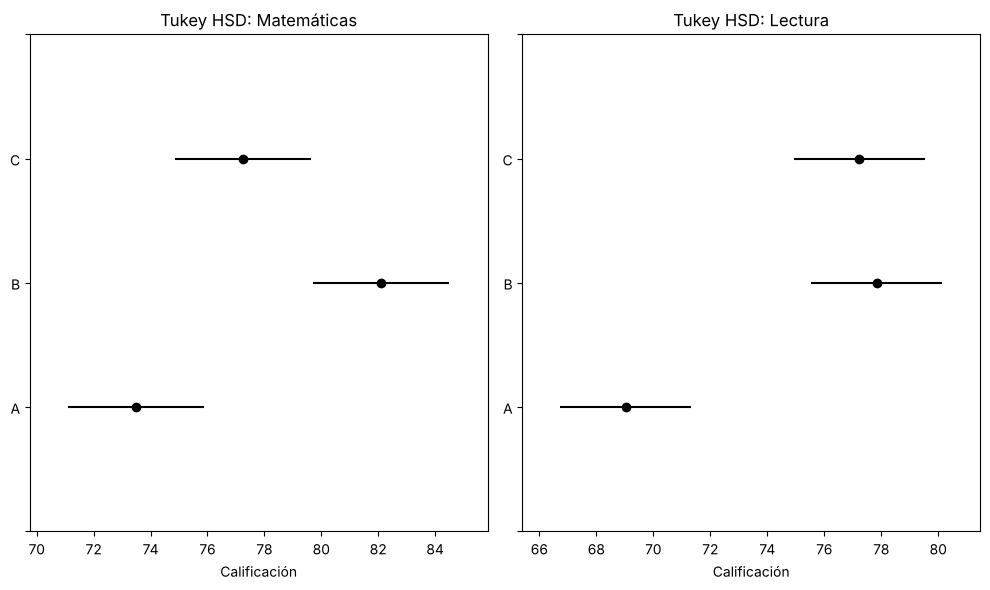

In [11]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tukey Matemáticas
tukey_mat.plot_simultaneous(ax=axes[0])
axes[0].set_title('Tukey HSD: Matemáticas')
axes[0].set_xlabel('Calificación')

# Tukey Lectura
tukey_lec.plot_simultaneous(ax=axes[1])
axes[1].set_title('Tukey HSD: Lectura')
axes[1].set_xlabel('Calificación')

plt.tight_layout()
plt.show()

In [12]:
# Verificación de supuestos - Normalidad multivariada
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

# Test de Mardia para normalidad multivariada
def mardia_test(data, alpha=0.05):
    """
    Implementación simplificada del test de Mardia
    """
    n, p = data.shape
    mean = np.mean(data, axis=0)
    centered = data - mean
    S = np.cov(data, rowvar=False)
    S_inv = np.linalg.inv(S)
    
    # Asimetría multivariada
    b1p = 0
    for i in range(n):
        for j in range(n):
            b1p += (centered[i] @ S_inv @ centered[j])**3
    b1p = b1p / (n**2)
    
    # Curtosis multivariada
    b2p = 0
    for i in range(n):
        b2p += (centered[i] @ S_inv @ centered[i])**2
    b2p = b2p / n
    
    # Estadísticos de prueba
    skewness_stat = n * b1p / 6
    kurtosis_stat = (b2p - p*(p+2)) / np.sqrt(8*p*(p+2)/n)
    
    # p-valores
    p_skewness = 1 - stats.chi2.cdf(skewness_stat, p*(p+1)*(p+2)/6)
    p_kurtosis = 2 * (1 - stats.norm.cdf(abs(kurtosis_stat)))
    
    return {
        'Skewness statistic': skewness_stat,
        'Skewness p-value': p_skewness,
        'Kurtosis statistic': kurtosis_stat,
        'Kurtosis p-value': p_kurtosis
    }

# Aplicar test por grupo
for metodo in df['Metodo'].unique():
    subset = df[df['Metodo'] == metodo][['Matematicas', 'Lectura']].values
    print(f"Método {metodo}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")
    
    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Método A:
  Skewness statistic: 1.9333
  Skewness p-value: 0.7480
  Kurtosis statistic: -1.1241
  Kurtosis p-value: 0.2610
  ✅ Normalidad multivariada aceptable

Método B:
  Skewness statistic: 4.0213
  Skewness p-value: 0.4031
  Kurtosis statistic: -0.2271
  Kurtosis p-value: 0.8203
  ✅ Normalidad multivariada aceptable

Método C:
  Skewness statistic: 3.1460
  Skewness p-value: 0.5337
  Kurtosis statistic: -0.9106
  Kurtosis p-value: 0.3625
  ✅ Normalidad multivariada aceptable



In [13]:
#  Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

def box_m_test(data, groups):
    """
    Implementación del test M de Box
    """
    group_names = groups.unique()
    k = len(group_names)
    p = data.shape[1]
    
    # Tamaños de muestra
    ns = [len(data[groups == g]) for g in group_names]
    n_total = sum(ns)
    
    # Matrices de covarianza por grupo
    covs = []
    for g in group_names:
        subset = data[groups == g]
        covs.append(np.cov(subset, rowvar=False))
    
    # Covarianza pooled
    pooled_cov = sum([(n-1) * cov for n, cov in zip(ns, covs)]) / (n_total - k)
    
    # Estadístico M
    M = (n_total - k) * np.log(np.linalg.det(pooled_cov))
    for n, cov in zip(ns, covs):
        M -= (n - 1) * np.log(np.linalg.det(cov))
    
    # Factor de corrección
    c = (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    c *= sum([1/(n-1) for n in ns]) - 1/(n_total - k)
    
    # Estadístico de prueba
    chi2_stat = M * (1 - c)
    
    # Grados de libertad
    df = p * (p + 1) * (k - 1) / 2
    
    # p-valor
    p_value = 1 - stats.chi2.cdf(chi2_stat, df)
    
    return {
        'M statistic': M,
        'Chi-square': chi2_stat,
        'df': df,
        'p-value': p_value
    }

# Aplicar Box's M
resultado_box = box_m_test(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 2.3240
  Chi-square: 2.2469
  df: 6.0000
  p-value: 0.8957

✅ No se rechaza H₀: Las matrices de covarianza son homogéneas


In [14]:
#  Preguntas de análisis
print(" PREGUNTAS DE ANÁLISIS:")
print("\n1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?")
print("2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?")
print("3. ¿Qué pares de grupos son significativamente diferentes?")
print("4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?")
print("5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?")



 PREGUNTAS DE ANÁLISIS:

1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?
2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?
3. ¿Qué pares de grupos son significativamente diferentes?
4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?
5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?


## Respuestas — Ejemplo de métodos de enseñanza

**1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?**

La **Lambda de Wilks** (Λ = 0.6317, F(4, 172) = 11.10, p < 0.001). Es el estadístico de uso general y es apropiado aquí porque se cumplen los supuestos: el diseño es balanceado (n = 30 por grupo), la normalidad multivariada es aceptable en los tres grupos y la prueba M de Box no rechaza la homogeneidad de covarianzas (p = 0.896). La Traza de Pillai (0.379) sería la elección si alguno de esos supuestos fallara, porque es la más robusta; como no fallan, su ventaja no es necesaria. La Raíz Mayor de Roy solo considera la primera dimensión y su F es una cota superior, así que tiende a ser optimista. En cualquier caso los cuatro estadísticos coinciden (p < 0.001), por lo que la conclusión no depende de cuál se elija: se rechaza H₀ de igualdad de vectores de medias. El tamaño del efecto multivariado es η² = 1 − Λ^(1/2) ≈ 0.21.

**2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?**

**Lectura**. En los ANOVA univariados, Lectura tiene F(2, 87) = 13.13 (p < 0.001) y η² = 1451.7 / 6259.5 ≈ 0.23, mientras que Matemáticas tiene F(2, 87) = 9.22 (p = 0.0002) y η² = 1117.8 / 6394.3 ≈ 0.17. Ambas son significativas incluso con la corrección de Bonferroni (α = 0.025), pero el método de enseñanza explica una proporción mayor de la varianza de Lectura.

**3. ¿Qué pares de grupos son significativamente diferentes?**

Según Tukey HSD (FWER = 0.05):

| Par | Matemáticas | Lectura |
|---|---|---|
| A vs B | Sí (dif. = 8.61, p = 0.0001) | Sí (dif. = 8.81, p < 0.001) |
| A vs C | No (dif. = 3.75, p = 0.156) | Sí (dif. = 8.20, p = 0.0001) |
| B vs C | Sí, marginal (dif. = −4.86, p = 0.046) | No (dif. = −0.61, p = 0.946) |

El método B (activo) supera al A (tradicional) en ambas materias. El C (híbrido) supera al A solo en Lectura, y B supera a C solo en Matemáticas, con una diferencia apenas significativa (el intervalo casi toca el cero).

**4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?**

Sí:

- **Normalidad multivariada (Mardia):** en los tres grupos los p-valores de asimetría (0.75, 0.40, 0.53) y de curtosis (0.26, 0.82, 0.36) son mayores a 0.05.
- **Homogeneidad de covarianzas (M de Box):** χ²(6) = 2.25, p = 0.896, no se rechaza H₀.
- **Independencia y tamaño de muestra:** las observaciones son independientes por construcción y los grupos son iguales (n = 30), mucho mayores que el número de variables dependientes (2).

La implicación es que los p-valores del MANOVA son confiables, se puede interpretar la Lambda de Wilks sin recurrir a Pillai y los post-hoc (ANOVA y Tukey, que suponen varianzas iguales) también son válidos.

**5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?**

Son dos lecturas del mismo problema: ambos se basan en los eigenvalores de **W⁻¹B** (variación entre grupos relativa a la variación dentro de grupos). El MANOVA los resume en un estadístico para probar *si* los grupos difieren; el LDA usa los eigenvectores para describir *en qué dirección* difieren (las funciones discriminantes).

Con 3 grupos y 2 variables hay 2 eigenvalores: λ₁ = 0.5346 (la Raíz de Roy) y λ₂ = 0.5662 − 0.5346 = 0.0316 (porque Hotelling-Lawley es la suma). Con ellos se recuperan los demás estadísticos: Λ = 1 / [(1 + λ₁)(1 + λ₂)] = 0.6317 y Pillai = Σ λᵢ/(1 + λᵢ) = 0.379. La primera función discriminante concentra λ₁/(λ₁ + λ₂) ≈ 94.4 % de la separación entre métodos, con correlación canónica √(λ₁/(1 + λ₁)) ≈ 0.59, por lo que las diferencias son prácticamente unidimensionales. La siguiente celda lo verifica numéricamente.

In [15]:
# Verificación de la respuesta 5: eigenvalores de W^-1 B y relación con el LDA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

def eigen_manova(X, y):
    """Eigenvalores de W^-1 B (W: dentro de grupos, B: entre grupos)"""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    media_global = X.mean(axis=0)
    p = X.shape[1]
    W = np.zeros((p, p))
    B = np.zeros((p, p))
    for g in np.unique(y):
        Xg = X[y == g]
        d = Xg - Xg.mean(axis=0)
        W += d.T @ d
        dm = (Xg.mean(axis=0) - media_global).reshape(-1, 1)
        B += len(Xg) * dm @ dm.T
    eig = np.sort(np.linalg.eigvals(np.linalg.inv(W) @ B).real)[::-1]
    return eig[:min(p, len(np.unique(y)) - 1)], W, B

eig, _, _ = eigen_manova(df[['Matematicas', 'Lectura']], df['Metodo'])
print("Eigenvalores de W^-1 B:", eig.round(4))
print(f"Roy (λ1)                 = {eig[0]:.4f}")
print(f"Hotelling-Lawley (Σλ)    = {eig.sum():.4f}")
print(f"Wilks (Π 1/(1+λ))        = {np.prod(1 / (1 + eig)):.4f}")
print(f"Pillai (Σ λ/(1+λ))       = {np.sum(eig / (1 + eig)):.4f}")

lda = LinearDiscriminantAnalysis().fit(df[['Matematicas', 'Lectura']], df['Metodo'])
print("\nProporción de separación por función discriminante (LDA):",
      lda.explained_variance_ratio_.round(4))
print("Proporción a partir de los eigenvalores:                 ", (eig / eig.sum()).round(4))

Eigenvalores de W^-1 B: [0.5346 0.0316]
Roy (λ1)                 = 0.5346
Hotelling-Lawley (Σλ)    = 0.5662
Wilks (Π 1/(1+λ))        = 0.6317
Pillai (Σ λ/(1+λ))       = 0.3790

Proporción de separación por función discriminante (LDA): [0.9442 0.0558]
Proporción a partir de los eigenvalores:                  [0.9442 0.0558]


# Actividad MANOVA

Ahora repite todo para el siguiente dataset de load_iris

In [16]:
# Celda 3: Cargar el dataset Iris (datos reales)
# El dataset Iris contiene mediciones de 3 especies de flores
iris = load_iris()

# Crear DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['Especie'] = iris.target_names[iris.target]

# Renombrar columnas para claridad
df.columns = ['Longitud_Sepalo', 'Ancho_Sepalo', 
              'Longitud_Petalo', 'Ancho_Petalo', 'Especie']

print(f"Forma del dataset: {df.shape}")
print(f"Especies: {df['Especie'].unique()}")
print(f"Observaciones por especie:")
print(df['Especie'].value_counts())
df.head(10)

Forma del dataset: (150, 5)
Especies: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
Observaciones por especie:
Especie
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,Longitud_Sepalo,Ancho_Sepalo,Longitud_Petalo,Ancho_Petalo,Especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [17]:
# Estadísticas descriptivas por especie
variables = ['Longitud_Sepalo', 'Ancho_Sepalo', 'Longitud_Petalo', 'Ancho_Petalo']

print("ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: \n")
estadisticas = df.groupby('Especie')[variables].agg(['mean', 'std', 'min', 'max']).round(2)
print(estadisticas.T)

ESTADÍSTICAS DESCRIPTIVAS POR ESPECIE: 

Especie               setosa  versicolor  virginica
Longitud_Sepalo mean    5.01        5.94       6.59
                std     0.35        0.52       0.64
                min     4.30        4.90       4.90
                max     5.80        7.00       7.90
Ancho_Sepalo    mean    3.43        2.77       2.97
                std     0.38        0.31       0.32
                min     2.30        2.00       2.20
                max     4.40        3.40       3.80
Longitud_Petalo mean    1.46        4.26       5.55
                std     0.17        0.47       0.55
                min     1.00        3.00       4.50
                max     1.90        5.10       6.90
Ancho_Petalo    mean    0.25        1.33       2.03
                std     0.11        0.20       0.27
                min     0.10        1.00       1.40
                max     0.60        1.80       2.50


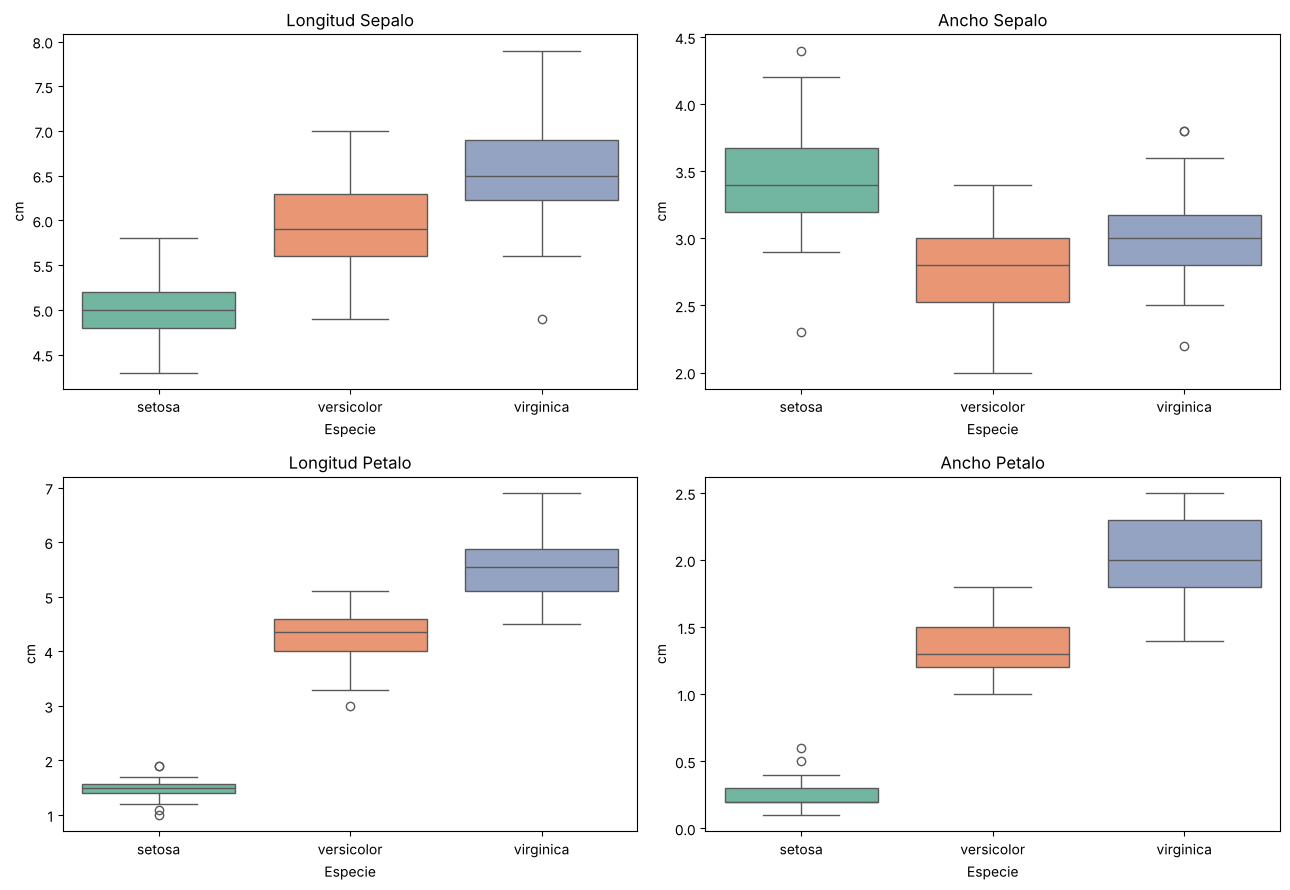

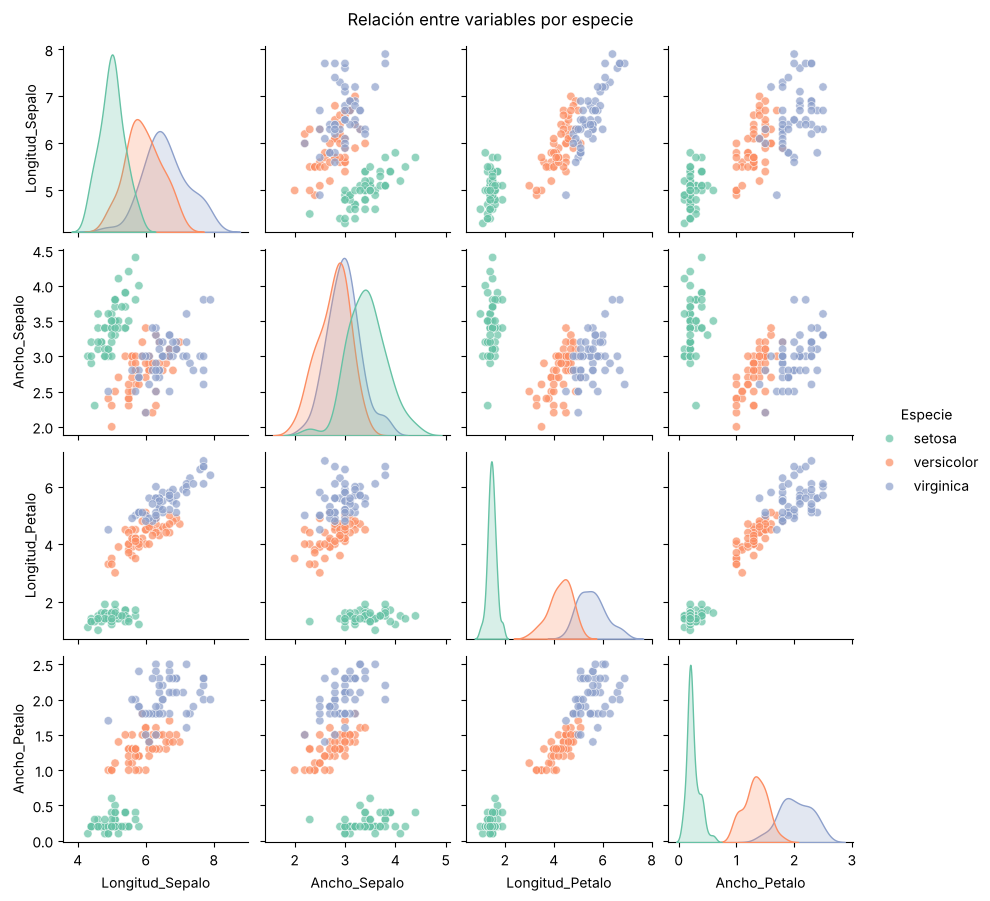

In [18]:
# Visualización
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, var in zip(axes.ravel(), variables):
    sns.boxplot(x='Especie', y=var, data=df, ax=ax, palette='Set2')
    ax.set_title(var.replace('_', ' '))
    ax.set_xlabel('Especie')
    ax.set_ylabel('cm')
plt.tight_layout()
plt.show()

# Dispersión por pares de variables
g = sns.pairplot(df, hue='Especie', palette='Set2', height=2.2, plot_kws={'alpha': 0.7})
g.fig.suptitle('Relación entre variables por especie', y=1.02)
plt.show()

MATRIZ DE CORRELACIÓN

                 Longitud_Sepalo  Ancho_Sepalo  Longitud_Petalo  Ancho_Petalo
Longitud_Sepalo           1.0000       -0.1176           0.8718        0.8179
Ancho_Sepalo             -0.1176        1.0000          -0.4284       -0.3661
Longitud_Petalo           0.8718       -0.4284           1.0000        0.9629
Ancho_Petalo              0.8179       -0.3661           0.9629        1.0000


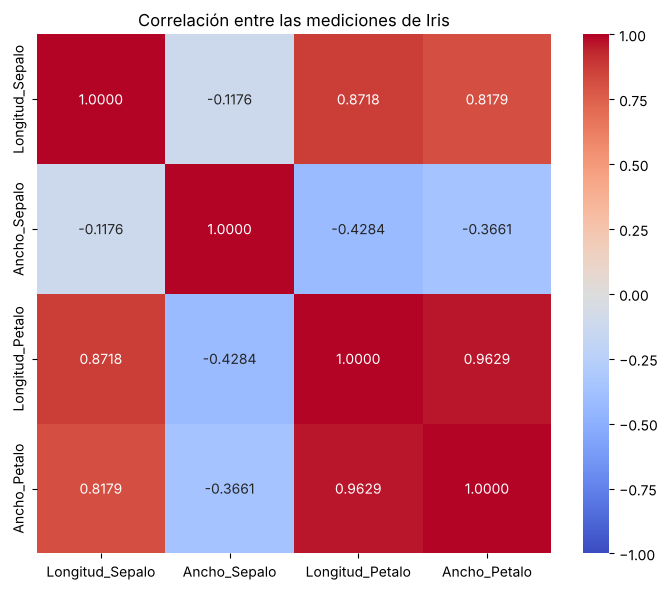

In [19]:
# Matriz de correlación
print("MATRIZ DE CORRELACIÓN\n")
print(df[variables].corr().round(4))

plt.figure(figsize=(7, 6))
sns.heatmap(df[variables].corr(), annot=True, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, fmt='.4f')
plt.title('Correlación entre las mediciones de Iris')
plt.tight_layout()
plt.show()

In [20]:
# MANOVA - Prueba principal
print("MANOVA \n")

formula = ' + '.join(variables) + ' ~ Especie'
manova = MANOVA.from_formula(formula, data=df)
resultado = manova.mv_test()

print(resultado)

MANOVA 

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0170 4.0000 144.0000 2086.7720 0.0000
         Pillai's trace  0.9830 4.0000 144.0000 2086.7720 0.0000
 Hotelling-Lawley trace 57.9659 4.0000 144.0000 2086.7720 0.0000
    Roy's greatest root 57.9659 4.0000 144.0000 2086.7720 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        Especie          Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0234 8.0000 288.0000  199.1453 0.0000
         Pillai's trace  1.1919 8.00

In [21]:
# Extraer resultados de los cuatro estadísticos
print("=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===\n")

resultados_mv = manova.mv_test().results['Especie']['stat']

print("Estadísticos de prueba:")
print(resultados_mv.astype(float).round(4))

=== RESULTADOS DE LOS CUATRO ESTADÍSTICOS ===

Estadísticos de prueba:
                          Value  Num DF    Den DF    F Value  Pr > F
Wilks' lambda            0.0234     8.0  288.0000   199.1453     0.0
Pillai's trace           1.1919     8.0  290.0000    53.4665     0.0
Hotelling-Lawley trace  32.4773     8.0  203.4024   582.1970     0.0
Roy's greatest root     32.1919     4.0  145.0000  1166.9574     0.0


In [22]:
# Interpretación de resultados
print("=== INTERPRETACIÓN DE RESULTADOS ===\n")

for estadistico in resultados_mv.index:
    p_valor = float(resultados_mv.loc[estadistico, 'Pr > F'])
    valor = float(resultados_mv.loc[estadistico, 'Value'])
    F = float(resultados_mv.loc[estadistico, 'F Value'])
    estado = "SIGNIFICATIVO" if p_valor < 0.05 else "NO SIGNIFICATIVO"
    print(f"{estadistico}: Valor = {valor:.4f}, F = {F:.2f}, p = {p_valor:.2e} → {estado}")

# Tamaño del efecto multivariado a partir de Wilks
wilks = float(resultados_mv.loc["Wilks' lambda", 'Value'])
s = min(len(variables), df['Especie'].nunique() - 1)
print(f"\nTamaño del efecto multivariado: η² = 1 - Λ^(1/{s}) = {1 - wilks**(1/s):.4f}")

print("\nConclusión:")
print("Los cuatro estadísticos son significativos (p < 0.05): las tres especies")
print("difieren en el vector conjunto de medias de las cuatro mediciones.")

=== INTERPRETACIÓN DE RESULTADOS ===

Wilks' lambda: Valor = 0.0234, F = 199.15, p = 1.37e-112 → SIGNIFICATIVO
Pillai's trace: Valor = 1.1919, F = 53.47, p = 9.74e-53 → SIGNIFICATIVO
Hotelling-Lawley trace: Valor = 32.4773, F = 582.20, p = 1.08e-135 → SIGNIFICATIVO
Roy's greatest root: Valor = 32.1919, F = 1166.96, p = 3.79e-109 → SIGNIFICATIVO

Tamaño del efecto multivariado: η² = 1 - Λ^(1/2) = 0.8469

Conclusión:
Los cuatro estadísticos son significativos (p < 0.05): las tres especies
difieren en el vector conjunto de medias de las cuatro mediciones.


In [23]:
# ANOVA univariado post-hoc (con corrección de Bonferroni)
print("=== ANOVA UNIVARIADO POST-HOC ===\n")

alpha = 0.05
alpha_bonferroni = alpha / len(variables)  # 4 variables dependientes

resumen = []
for var in variables:
    modelo = ols(f'{var} ~ Especie', data=df).fit()
    anova = sm.stats.anova_lm(modelo, typ=2)
    print(f"ANOVA para {var}:")
    print(anova.round(4), "\n")
    F = anova.loc['Especie', 'F']
    p = anova.loc['Especie', 'PR(>F)']
    eta2 = anova.loc['Especie', 'sum_sq'] / anova['sum_sq'].sum()
    resumen.append({'Variable': var, 'F': F, 'p': p, 'eta2': eta2,
                    'Significativo': p < alpha_bonferroni})

print("Corrección de Bonferroni:")
print(f"   α original = {alpha}")
print(f"   α ajustado = {alpha_bonferroni}\n")

resumen_anova = pd.DataFrame(resumen).set_index('Variable').sort_values('eta2', ascending=False)
print(resumen_anova.to_string(formatters={'F': '{:.2f}'.format, 'p': '{:.2e}'.format,
                                          'eta2': '{:.4f}'.format}))

=== ANOVA UNIVARIADO POST-HOC ===

ANOVA para Longitud_Sepalo:
           sum_sq     df         F  PR(>F)
Especie   63.2121    2.0  119.2645     0.0
Residual  38.9562  147.0       NaN     NaN 

ANOVA para Ancho_Sepalo:
           sum_sq     df      F  PR(>F)
Especie   11.3449    2.0  49.16     0.0
Residual  16.9620  147.0    NaN     NaN 

ANOVA para Longitud_Petalo:
            sum_sq     df          F  PR(>F)
Especie   437.1028    2.0  1180.1612     0.0
Residual   27.2226  147.0        NaN     NaN 

ANOVA para Ancho_Petalo:
           sum_sq     df         F  PR(>F)
Especie   80.4133    2.0  960.0071     0.0
Residual   6.1566  147.0       NaN     NaN 

Corrección de Bonferroni:
   α original = 0.05
   α ajustado = 0.0125

                      F        p   eta2  Significativo
Variable                                              
Longitud_Petalo 1180.16 2.86e-91 0.9414           True
Ancho_Petalo     960.01 4.17e-85 0.9289           True
Longitud_Sepalo  119.26 1.67e-31 0.6187        

In [24]:
# Comparaciones múltiples post-hoc (Tukey HSD)
print(" COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) \n")

tukey = {}
for var in variables:
    tukey[var] = pairwise_tukeyhsd(df[var], df['Especie'], alpha=0.05)
    print(f"Tukey HSD para {var}:")
    print(tukey[var], "\n")

 COMPARACIONES MÚLTIPLES POST-HOC (TUKEY HSD) 



Tukey HSD para Longitud_Sepalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     0.93   0.0 0.6862 1.1738   True
    setosa  virginica    1.582   0.0 1.3382 1.8258   True
versicolor  virginica    0.652   0.0 0.4082 0.8958   True
--------------------------------------------------------- 



Tukey HSD para Ancho_Sepalo:
    Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1     group2   meandiff p-adj   lower   upper  reject
------------------------------------------------------------
    setosa versicolor   -0.658    0.0 -0.8189 -0.4971   True
    setosa  virginica   -0.454    0.0 -0.6149 -0.2931   True
versicolor  virginica    0.204 0.0088  0.0431  0.3649   True
------------------------------------------------------------ 



Tukey HSD para Longitud_Petalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor    2.798   0.0 2.5942 3.0018   True
    setosa  virginica     4.09   0.0 3.8862 4.2938   True
versicolor  virginica    1.292   0.0 1.0882 1.4958   True
--------------------------------------------------------- 



Tukey HSD para Ancho_Petalo:
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
    setosa versicolor     1.08   0.0 0.9831 1.1769   True
    setosa  virginica     1.78   0.0 1.6831 1.8769   True
versicolor  virginica      0.7   0.0 0.6031 0.7969   True
--------------------------------------------------------- 



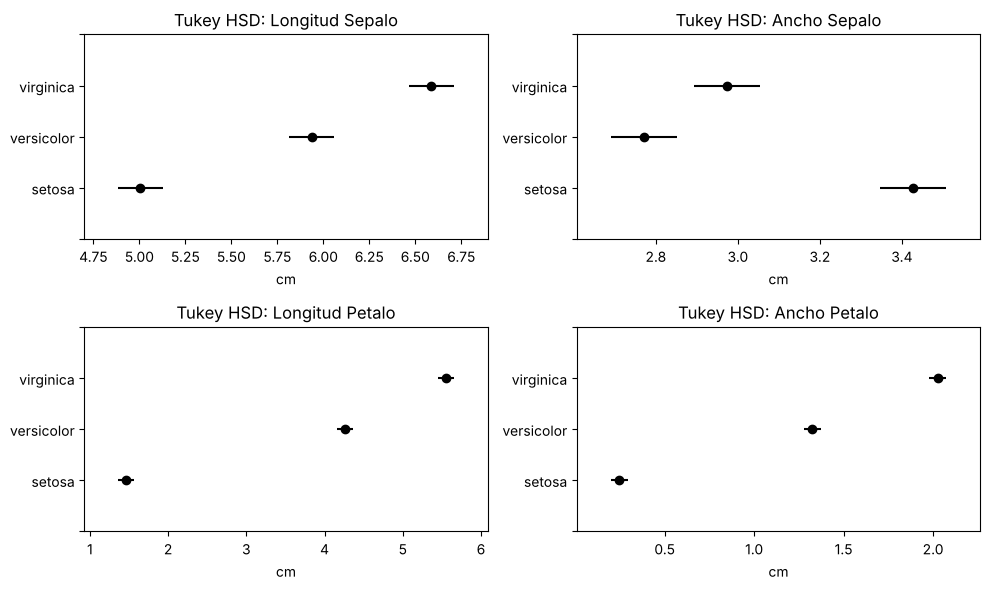

In [25]:
# Visualización de Tukey HSD
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, var in zip(axes.ravel(), variables):
    tukey[var].plot_simultaneous(ax=ax)
    ax.set_title(f"Tukey HSD: {var.replace('_', ' ')}")
    ax.set_xlabel('cm')
plt.tight_layout()
plt.show()

In [26]:
# Verificación de supuestos - Normalidad multivariada (Mardia)
print("=== VERIFICACIÓN DE SUPUESTOS ===\n")
print("--- Normalidad Multivariada ---\n")

for especie in df['Especie'].unique():
    subset = df[df['Especie'] == especie][variables].values
    print(f"Especie {especie}:")
    resultado = mardia_test(subset)
    for key, value in resultado.items():
        print(f"  {key}: {value:.4f}")

    if resultado['Skewness p-value'] > 0.05 and resultado['Kurtosis p-value'] > 0.05:
        print("  ✅ Normalidad multivariada aceptable")
    else:
        print("  ⚠️ Posible violación de normalidad multivariada")
    print()

# Complemento: normalidad univariada (Shapiro-Wilk) por especie y variable
print("--- Normalidad univariada (Shapiro-Wilk, p-valores) ---\n")
shapiro = pd.DataFrame({
    especie: [stats.shapiro(df[df['Especie'] == especie][var]).pvalue for var in variables]
    for especie in df['Especie'].unique()
}, index=variables)
print(shapiro.round(4))

=== VERIFICACIÓN DE SUPUESTOS ===

--- Normalidad Multivariada ---

Especie setosa:
  Skewness statistic: 24.1551
  Skewness p-value: 0.2357
  Kurtosis statistic: 0.7587
  Kurtosis p-value: 0.4480
  ✅ Normalidad multivariada aceptable

Especie versicolor:
  Skewness statistic: 23.7039
  Skewness p-value: 0.2556
  Kurtosis statistic: -1.0342
  Kurtosis p-value: 0.3010
  ✅ Normalidad multivariada aceptable

Especie virginica:
  Skewness statistic: 24.7257
  Skewness p-value: 0.2121
  Kurtosis statistic: -0.3384
  Kurtosis p-value: 0.7350
  ✅ Normalidad multivariada aceptable

--- Normalidad univariada (Shapiro-Wilk, p-valores) ---

                 setosa  versicolor  virginica
Longitud_Sepalo  0.4595      0.4647     0.2583
Ancho_Sepalo     0.2715      0.3380     0.1809
Longitud_Petalo  0.0548      0.1585     0.1098
Ancho_Petalo     0.0000      0.0273     0.0870


In [27]:
# Verificación de supuestos - Homogeneidad de covarianzas (Box's M)
print(" Homogeneidad de Matrices de Covarianza (Box's M) \n")

resultado_box = box_m_test(df[variables], df['Especie'])
print("Resultados del test M de Box:")
for key, value in resultado_box.items():
    print(f"  {key}: {value:.4f}")

if resultado_box['p-value'] > 0.05:
    print("\n✅ No se rechaza H₀: Las matrices de covarianza son homogéneas")
else:
    print("\n⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas")
    print("   → Considerar usar Pillai's Trace (más robusto)")

# Complemento: homogeneidad de varianzas univariada (Levene)
print("\nTest de Levene por variable (p-valores):")
for var in variables:
    p = stats.levene(*[df[df['Especie'] == e][var] for e in df['Especie'].unique()]).pvalue
    print(f"  {var}: p = {p:.2e}")

 Homogeneidad de Matrices de Covarianza (Box's M) 

Resultados del test M de Box:
  M statistic: 146.6632
  Chi-square: 140.9430
  df: 20.0000
  p-value: 0.0000

⚠️ Se rechaza H₀: Posible violación de homogeneidad de covarianzas
   → Considerar usar Pillai's Trace (más robusto)

Test de Levene por variable (p-valores):
  Longitud_Sepalo: p = 2.26e-03
  Ancho_Sepalo: p = 5.56e-01
  Longitud_Petalo: p = 3.13e-08
  Ancho_Petalo: p = 2.26e-08


Eigenvalores de W^-1 B: [32.1919  0.2854]
Roy (λ1)              = 32.1919
Hotelling-Lawley (Σλ) = 32.4773
Wilks (Π 1/(1+λ))     = 0.0234
Pillai (Σ λ/(1+λ))    = 1.1919
Correlaciones canónicas: [0.9848 0.4712]

Proporción de separación por función discriminante (LDA): [0.9912 0.0088]
Exactitud de clasificación del LDA: 0.980

Coeficientes discriminantes estandarizados:
                   LD1    LD2
Longitud_Sepalo  0.431 -0.013
Ancho_Sepalo     0.527 -0.743
Longitud_Petalo -0.957  0.405
Ancho_Petalo    -0.581 -0.587

Correlación de cada variable con las funciones discriminantes:
                   LD1    LD2
Longitud_Sepalo -0.792 -0.218
Ancho_Sepalo     0.531 -0.758
Longitud_Petalo -0.985 -0.046
Ancho_Petalo    -0.973 -0.223


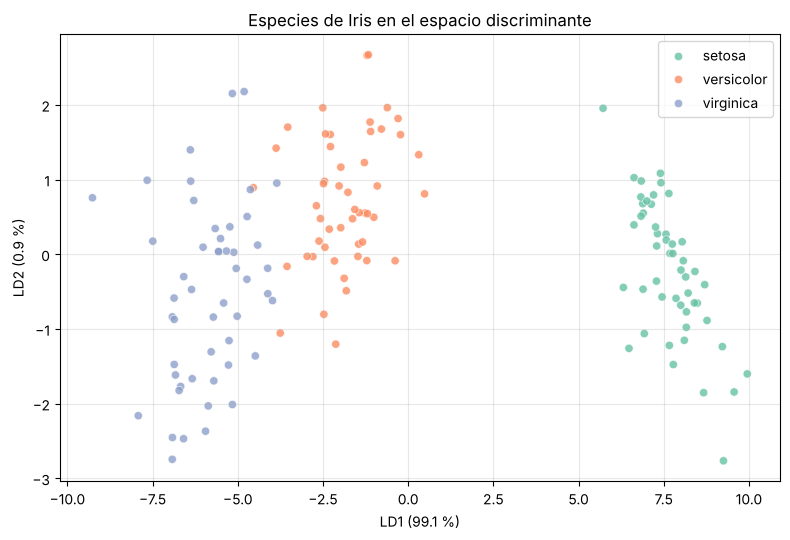

In [28]:
# LDA y su relación con el MANOVA
X = df[variables].values
y = df['Especie'].values

eig, W, B = eigen_manova(X, y)
print("Eigenvalores de W^-1 B:", eig.round(4))
print(f"Roy (λ1)              = {eig[0]:.4f}")
print(f"Hotelling-Lawley (Σλ) = {eig.sum():.4f}")
print(f"Wilks (Π 1/(1+λ))     = {np.prod(1 / (1 + eig)):.4f}")
print(f"Pillai (Σ λ/(1+λ))    = {np.sum(eig / (1 + eig)):.4f}")
print("Correlaciones canónicas:", np.sqrt(eig / (1 + eig)).round(4))

lda = LinearDiscriminantAnalysis().fit(X, y)
Z = lda.transform(X)
print("\nProporción de separación por función discriminante (LDA):",
      lda.explained_variance_ratio_.round(4))
print(f"Exactitud de clasificación del LDA: {lda.score(X, y):.3f}")

# Coeficientes estandarizados y correlaciones variable - función discriminante
sd_dentro = np.sqrt(np.diag(W / (len(X) - len(np.unique(y)))))
coef = pd.DataFrame(lda.scalings_[:, :2] * sd_dentro[:, None],
                    index=variables, columns=['LD1', 'LD2'])
estructura = pd.DataFrame([[np.corrcoef(X[:, j], Z[:, k])[0, 1] for k in range(2)]
                           for j in range(len(variables))],
                          index=variables, columns=['LD1', 'LD2'])
print("\nCoeficientes discriminantes estandarizados:")
print(coef.round(3))
print("\nCorrelación de cada variable con las funciones discriminantes:")
print(estructura.round(3))

plt.figure(figsize=(8, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette='Set2', alpha=0.8)
plt.xlabel(f'LD1 ({lda.explained_variance_ratio_[0]*100:.1f} %)')
plt.ylabel(f'LD2 ({lda.explained_variance_ratio_[1]*100:.1f} %)')
plt.title('Especies de Iris en el espacio discriminante')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Respuestas — Dataset Iris

**1. ¿Cuál de los cuatro estadísticos MANOVA es más apropiado y por qué?**

La **Traza de Pillai** (V = 1.192, F(8, 290) = 53.47, p < 0.001). A diferencia del ejemplo anterior, aquí la prueba M de Box rechaza la homogeneidad de matrices de covarianza (χ²(20) = 140.94, p < 0.001), y Pillai es el estadístico más robusto ante esa violación; además el diseño es balanceado (n = 50 por especie), que es justo la condición en la que Pillai conserva bien su nivel de significancia. De todas formas los cuatro estadísticos son significativos (Wilks Λ = 0.0234, Hotelling-Lawley = 32.48, Roy = 32.19, todos con p < 0.001), así que la conclusión es la misma: se rechaza H₀ y las tres especies difieren en su vector de medias. El efecto es enorme: η² = 1 − Λ^(1/2) ≈ 0.85.

**2. ¿Qué variable dependiente contribuye más a las diferencias entre grupos?**

La **longitud del pétalo**, seguida muy de cerca por el ancho del pétalo. Las cuatro variables son significativas con Bonferroni (α = 0.0125):

| Variable | F(2, 147) | η² |
|---|---|---|
| Longitud del pétalo | 1180.16 | 0.941 |
| Ancho del pétalo | 960.01 | 0.929 |
| Longitud del sépalo | 119.26 | 0.619 |
| Ancho del sépalo | 49.16 | 0.401 |

La especie explica más del 92 % de la varianza de las dos medidas del pétalo, contra 62 % y 40 % en las del sépalo. El LDA lo confirma: la longitud del pétalo tiene el coeficiente estandarizado más grande en la primera función discriminante (|0.96|) y la correlación más alta con ella (|0.99|).

**3. ¿Qué pares de grupos son significativamente diferentes?**

**Todos los pares en las cuatro variables** (Tukey HSD, FWER = 0.05): setosa–versicolor, setosa–virginica y versicolor–virginica. La comparación menos marcada es versicolor–virginica en el ancho del sépalo (diferencia = 0.20 cm, p = 0.0088); las demás tienen p < 0.001. Setosa es la especie más distinta (pétalos mucho más cortos y angostos, sépalos más anchos), mientras que versicolor y virginica son las más parecidas entre sí. En el ancho del sépalo el orden cambia respecto a las otras variables: setosa > virginica > versicolor.

**4. ¿Se cumplen los supuestos del MANOVA? ¿Qué implicaciones tiene?**

Parcialmente:

- **Normalidad multivariada (Mardia):** aceptable en las tres especies (p de asimetría 0.24, 0.26, 0.21; p de curtosis 0.45, 0.30, 0.74). A nivel univariado, Shapiro-Wilk sí detecta desviaciones en el ancho del pétalo de setosa (p < 0.001) y de versicolor (p = 0.027), porque esa variable toma muy pocos valores distintos (está medida con una décima de cm de precisión).
- **Homogeneidad de covarianzas (M de Box):** **no se cumple** (p < 0.001). Levene lo confirma en tres de las cuatro variables (todas menos el ancho del sépalo): setosa tiene mucha menos variabilidad en los pétalos que las otras dos especies.
- **Independencia y tamaño de muestra:** grupos iguales de 50, muy por encima de las 4 variables dependientes.
- **Multicolinealidad:** la longitud y el ancho del pétalo están muy correlacionados (r = 0.96), así que aportan información en buena parte redundante, aunque no llega a hacer singular la matriz.

Implicaciones: conviene reportar Pillai en lugar de Wilks, y tomar con cautela los p-valores exactos. Aun así la conclusión es sólida, porque el diseño balanceado atenúa el efecto de las covarianzas desiguales, la prueba de Box es muy sensible con muestras de este tamaño y el efecto es tan grande que ninguna corrección razonable cambiaría el resultado. Donde sí importa es en los post-hoc: ANOVA y Tukey suponen varianzas iguales, por lo que una alternativa más rigurosa sería Welch con Games-Howell.

**5. ¿Cómo se relacionan los resultados del LDA con los del MANOVA?**

Ambos salen de los eigenvalores de W⁻¹B, que aquí son λ₁ = 32.19 y λ₂ = 0.285. La Raíz de Roy es λ₁, Hotelling-Lawley es su suma (32.48), y con ellos se reproducen Wilks (0.0234) y Pillai (1.192), como muestra la celda anterior. El MANOVA dice que las especies difieren; el LDA dice cómo:

- La primera función discriminante concentra el **99.1 %** de la separación (correlación canónica 0.985) y la segunda apenas el 0.9 % (0.471). Por eso Roy y Hotelling-Lawley son casi iguales: la diferencia entre especies es prácticamente unidimensional.
- Esa dimensión es sobre todo un contraste del tamaño del pétalo, que coincide con las variables de mayor F en los ANOVA.
- En la gráfica, setosa queda completamente aislada sobre LD1 y versicolor y virginica se traslapan un poco, lo mismo que mostró Tukey (el par más parecido). El LDA clasifica correctamente el 98 % de las flores, que es la contraparte práctica de un Λ de Wilks tan cercano a cero.

## Conclusión

En el ejemplo sintético los métodos de enseñanza producen diferencias moderadas (Λ = 0.63) con todos los supuestos cumplidos, por lo que Wilks es adecuado. En Iris las diferencias entre especies son muy grandes (Λ = 0.023), pero las covarianzas no son homogéneas, y lo correcto es apoyarse en la Traza de Pillai. En ambos casos el LDA muestra que casi toda la separación ocurre en una sola dimensión.